In [15]:
import gymnasium as gym
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation
import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import ale_py
import random
from collections import deque
import math
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import time

gym.register_envs(ale_py)

def setup_environment(env_name='ALE/AirRaid-v5'):
    # Create the base environment
    env = gym.make(env_name, frameskip=1)

    # Apply Atari preprocessing
    # Convert frames to grasycale, resize, normalize, and skip frames
    env = AtariPreprocessing(
        env=env,
        screen_size=84,
        frame_skip=4,
        grayscale_obs=True,
        scale_obs=False
    )

    # Stack the last 4 frames to give the agent a sense of motion
    env = FrameStackObservation(env, stack_size=4)

    return env


class ReplayBuffer:
    def __init__(self, capacity):
        # automatically removes the last element when it reaches 'capacity'
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        """Saves a transition"""
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        """Randomly samples a batch of transitions for training"""
        batch = random.sample(self.buffer, batch_size)

        # unzip the batch into separate tuples
        states, actions, rewards, next_states, dones = zip(*batch)

        # convert to pytorch tensors
        states = torch.from_numpy(np.array(states, dtype=np.uint8))
        actions = torch.tensor(actions, dtype=torch.int64)
        rewards = torch.tensor(rewards, dtype=torch.float32)
        next_states = torch.from_numpy(np.array(next_states, dtype=np.uint8))
        dones = torch.tensor(dones, dtype=torch.float32)

        return states, actions, rewards, next_states, dones


    def __len__(self):
        return len(self.buffer)


class DQN(nn.Module):
    def __init__(self, input_shape, num_actions):
        super(DQN, self).__init__()

        # input_shape is (4, 84, 84)
        self.conv1 = nn.Conv2d(input_shape[0], 32, kernel_size=8, stride=4)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2)
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1)

        # the flattened size after the 3 conv layers
        # for 84x84 input, the spatial dimensions go: 84 -> 20 -> 9 -> 7
        # flattened size = 64 channels * 7 height * 7 width = 3136

        self.fc1 = nn.Linear(3136, 512)
        self.fc2 = nn.Linear(512, num_actions)

    def forward(self, x):
        # apply convolutions with ReLU activation
        x = x.float() / 255.0
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = torch.relu(self.conv3(x))

        # flatten the output for the linear layers
        x = x.view(x.size(0), -1)

        # apply full connected layers
        x = torch.relu(self.fc1(x))

        return self.fc2(x) # return logits as Q-values

class DQNAgent:
    def __init__(
        self, input_shape,
        num_actions, lr,
        gamma, batch_size,
        eps_start, eps_end,
        eps_decay):
        # store hyperparameters
        self.num_actions = num_actions
        self.gamma = gamma
        self.batch_size = batch_size
        self.eps_start = eps_start
        self.eps_end = eps_end
        self.eps_decay = eps_decay

        # internal step counter for epsilon decay
        self.steps_done = 0

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        # initialize networks and optimizer
        self.online_net = DQN(input_shape, num_actions).to(self.device)
        self.target_net = DQN(input_shape, num_actions).to(self.device)
        self.target_net.load_state_dict(self.online_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.online_net.parameters(), lr=lr)


    def select_action(self, state):
        """Epsilon-greedy action selection with built-in decay"""

        # calculate the current epsilon based on how many steps we have taken
        epsilon = self.eps_end + (self.eps_start - self.eps_end) * math.exp(-1. * self.steps_done / self.eps_decay)
        self.steps_done += 1

        # exploration
        if random.random() < epsilon:
            return random.randint(0, self.num_actions - 1)
        # exploitation
        else:
            state_tensors = torch.as_tensor(np.asarray(state)).unsqueeze(0).to(self.device)
            with torch.no_grad():
                q_values = self.online_net(state_tensors)
            return q_values.argmax().item()


    def optimize_model(self, memory):
        """Samples from memory and updates the online network"""
        if len(memory) < self.batch_size:
            return None

        # get a batch of 32 random samples
        states, actions, rewards, next_states, dones = memory.sample(self.batch_size)

        # Move all data to the hardware (gpu/cpu)
        states = states.to(self.device)
        actions = actions.to(self.device)
        rewards = rewards.to(self.device)
        next_states = next_states.to(self.device)
        dones = dones.to(self.device)

        # predict the current Q-value
        current_q_values = self.online_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        # calculate the target Q-value using the bellman equation
        with torch.no_grad():
            max_next_q_values = self.target_net(next_states).max(1)[0]
        target_q_values = rewards + (self.gamma * max_next_q_values * (1 - dones))

        # calculate the loss
        loss = F.mse_loss(current_q_values, target_q_values)

        # backpropagation
        self.optimizer.zero_grad()
        loss.backward()

        # gradient clipping
        torch.nn.utils.clip_grad_value_(self.online_net.parameters(), 100)

        #adjust weights
        self.optimizer.step()

        return loss.item()

def training_loop(
    # hyperparameters
    LR=1e-4,
    GAMMA=0.99,
    BATCH_SIZE=32,
    EPS_START=1.0,
    EPS_END=0.05,
    EPS_DECAY=50000,
    # training loop hyperparameters
    MEMORY_CAPACITY=100000,
    TARGET_UPDATE_FREQ=1000,
    NUM_EPISODES=500
):
    env = setup_environment("ALE/AirRaid-v5")

    input_shape = (4, 84, 84)
    num_actions = env.action_space.n

    agent = DQNAgent(
        input_shape=input_shape,
        num_actions=num_actions,
        lr=LR,
        batch_size=BATCH_SIZE,
        gamma=GAMMA,
        eps_start=EPS_START,
        eps_end=EPS_END,
        eps_decay=EPS_DECAY
    )

    memory = ReplayBuffer(MEMORY_CAPACITY)

    performance_data = []

    print("Starting training...")

    for episode in range(NUM_EPISODES):
        state, info = env.reset()

        episode_reward = 0.0
        episode_length = 0

        while True:
            # select action and interact with the environment
            action = agent.select_action(state)
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # clip reward
            # clipped_reward = reward
            clipped_reward = float(np.sign(reward))

            # save experience int the replay buffer
            memory.push(state, action, clipped_reward, next_state, done)

            # move to the next state
            state = next_state

            # accumulate stats
            episode_reward += float(reward)
            episode_length += 1

            # sample and optimize the model
            if agent.steps_done % 4 == 0:
                agent.optimize_model(memory)

            # periodically update the target network to match the online network
            if agent.steps_done % TARGET_UPDATE_FREQ == 0:
                agent.target_net.load_state_dict(agent.online_net.state_dict())

            if done:
                break

        # end of episode summary
        print(f"Episode: {episode + 1}/{NUM_EPISODES} | "
              f"Steps: {episode_length} | "
              f"Total Steps: {agent.steps_done} | "
              f"Reward: {episode_reward:.1f}")

        performance_data.append({
            "Episode": episode + 1,
            "Episode Length": episode_length,
            "Total Steps": agent.steps_done,
            "Reward": episode_reward
        })
    print("Training complete.")
    return performance_data, agent


def plot_performance(
    performance_data,
    window=20,
    x_axis="Episode",
    title="DQN Training on AirRaid",
    save_path=None
):
    """
    Plot reward and episode length with moving averages.

    Args:
        performance_data: list of dicts returned by training_loop()
        window: moving average window size (in episodes)
        x_axis: "Episode" or "Total Steps"
        title: figure title
        save_path: optional path (str or Path) to save the figure as an image
    """
    df = pd.DataFrame(performance_data)

    # moving averages (min_periods=1 so the line starts from the first episode)
    reward_ma = df["Reward"].rolling(window, min_periods=1).mean()
    reward_std = df["Reward"].rolling(window, min_periods=1).std().fillna(0)
    length_ma = df["Episode Length"].rolling(window, min_periods=1).mean()
    x = df[x_axis]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # --- Reward ---
    ax1.plot(x, df["Reward"], alpha=0.3, color="tab:blue", label="Episode reward")
    ax1.plot(x, reward_ma, color="tab:blue", linewidth=2,
             label=f"Moving average ({window} episodes)")
    ax1.fill_between(x, reward_ma - reward_std, reward_ma + reward_std,
                     color="tab:blue", alpha=0.15, label="±1 std")
    ax1.set_ylabel("Reward")
    ax1.set_title(title)
    ax1.grid(alpha=0.3)
    ax1.legend(loc="upper left")

    # --- Episode length ---
    ax2.plot(x, df["Episode Length"], alpha=0.3, color="tab:orange",
             label="Episode length")
    ax2.plot(x, length_ma, color="tab:orange", linewidth=2,
             label=f"Moving average ({window} episodes)")
    ax2.set_xlabel(x_axis)
    ax2.set_ylabel("Steps")
    ax2.grid(alpha=0.3)
    ax2.legend(loc="upper left")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=150)
        print(f"Plot saved to {save_path}")

    plt.show()
    return fig

Starting training...
Episode: 1/500 | Steps: 1328 | Total Steps: 1328 | Reward: 1400.0
Episode: 2/500 | Steps: 267 | Total Steps: 1595 | Reward: 375.0
Episode: 3/500 | Steps: 1268 | Total Steps: 2863 | Reward: 1275.0
Episode: 4/500 | Steps: 387 | Total Steps: 3250 | Reward: 375.0
Episode: 5/500 | Steps: 1133 | Total Steps: 4383 | Reward: 1450.0
Episode: 6/500 | Steps: 788 | Total Steps: 5171 | Reward: 950.0
Episode: 7/500 | Steps: 986 | Total Steps: 6157 | Reward: 725.0
Episode: 8/500 | Steps: 397 | Total Steps: 6554 | Reward: 625.0
Episode: 9/500 | Steps: 750 | Total Steps: 7304 | Reward: 875.0
Episode: 10/500 | Steps: 588 | Total Steps: 7892 | Reward: 375.0
Episode: 11/500 | Steps: 176 | Total Steps: 8068 | Reward: 275.0
Episode: 12/500 | Steps: 973 | Total Steps: 9041 | Reward: 1400.0
Episode: 13/500 | Steps: 708 | Total Steps: 9749 | Reward: 800.0
Episode: 14/500 | Steps: 369 | Total Steps: 10118 | Reward: 225.0
Episode: 15/500 | Steps: 1257 | Total Steps: 11375 | Reward: 1050.0
Ep

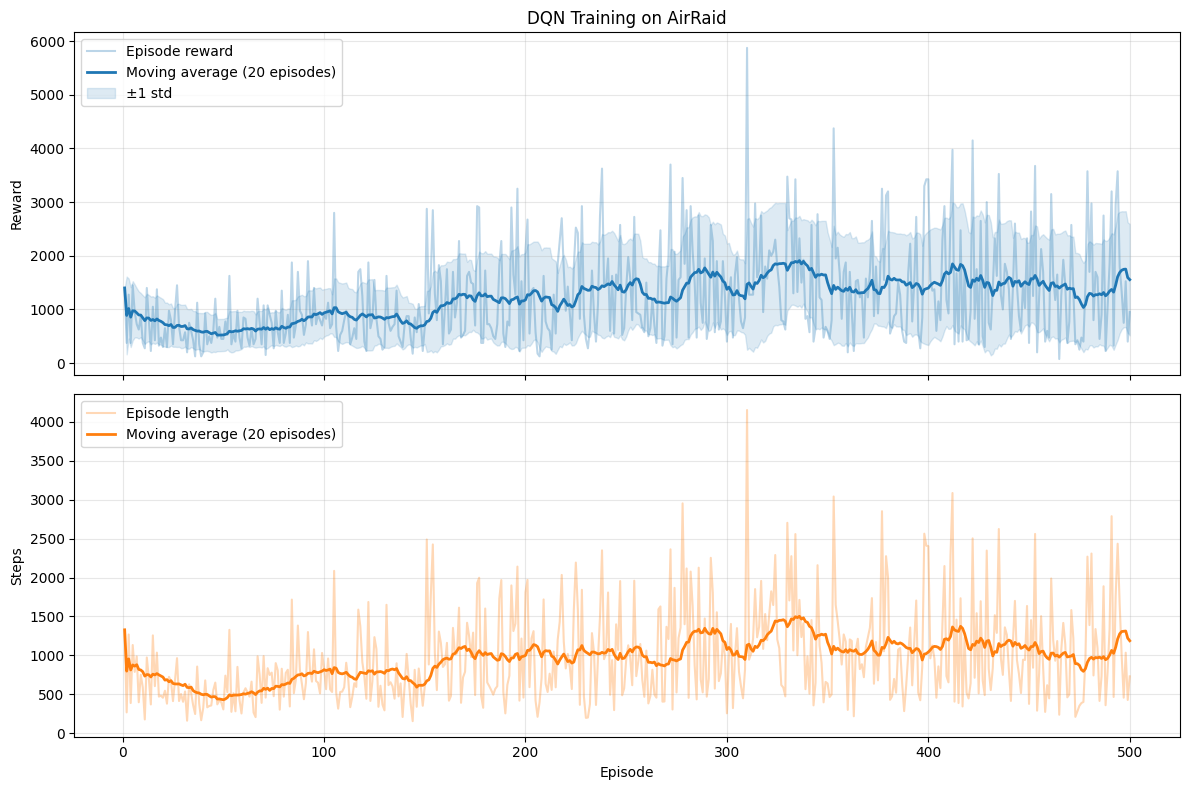

In [21]:
# Experiment 11: MSE Fast + clipped - Larger batch
start = time.perf_counter()
performance, agent = training_loop(
    # hyperparameters
    LR=1e-4,
    GAMMA=0.99,
    BATCH_SIZE=128,
    EPS_START=1.0,
    EPS_END=0.05,
    EPS_DECAY=50000,
    # training loop hyperparameters
    MEMORY_CAPACITY=100000,
    TARGET_UPDATE_FREQ=1000,
    NUM_EPISODES=500
)

elapsed_1 = time.perf_counter() - start
total_steps_1 = performance[-1]["Total Steps"]
print(f"Training time: {elapsed_1/60:.1f} min ({elapsed_1/3600:.2f} h)")
print(f"Speed: {total_steps_1/elapsed_1:.0f} steps/sec")

fig_1 = plot_performance(
    performance,
    window=20,
    x_axis="Episode",
    title="DQN Training on AirRaid",
    save_path=None
)


In [22]:
torch.save(agent.online_net.state_dict(),  "model_11_mse_fast_clipped_batch128.pth")
fig_1.savefig("training_curve_11_mse_fast_clipped_batch128.png", dpi=150, bbox_inches="tight")
# save training performance data
df = pd.DataFrame(performance)
df.to_csv("training_performance_11_mse_fast_clipped_batch128.csv", index=False)